# Optimal minibatch size of SGD-NICE

For $\tau$ from $1$ to $n$ we run SGD-NICE on California housing (linear least squares) with the stepsize of the convergence theorem
and count the gradients ($\tau$ per iteration) until $\mathbb{E}\|w^k - w^\star\|^2 \le 2\delta\|w^0 - w^\star\|^2$.
GD ($n$ gradients per iteration) is the reference.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

## Data
Same setup as `hw_2026_11_11/sgd_lin.ipynb`: log of the skewed features, standardize, clip, add bias.

In [2]:
data = fetch_california_housing()
raw, _, y, _ = train_test_split(data.data, data.target, test_size=0.2, random_state=2)
log_idx = [data.feature_names.index(s) for s in ["AveRooms", "AveBedrms", "Population", "AveOccup"]]
raw = raw.copy()
raw[:, log_idx] = np.log(raw[:, log_idx])
Z = np.clip((raw - raw.mean(axis=0)) / raw.std(axis=0), -3, 3)
X = np.hstack([Z, np.ones((len(Z), 1))])
N, D = X.shape
print(f"n = {N}, d = {D}")

n = 16512, d = 9


## Constants
$f_i(w) = \frac12(\langle x_i, w\rangle - y_i)^2$, $A''$ and $\mathrm{Var}[g(w^\star)]$ from Lemma 45, stepsize and iteration count from the theorem.

In [3]:
w_star = np.linalg.solve(X.T @ X, X.T @ y)
L_max = np.max(np.sum(X ** 2, axis=1))
eig = np.linalg.eigvalsh(X.T @ X / N)
mu, L = eig[0], eig[-1]
sigma2 = np.mean(np.sum((X * (X @ w_star - y)[:, None]) ** 2, axis=1))

W0 = np.zeros(D)
R0 = np.sum((W0 - w_star) ** 2)
DELTA = 5e-3                # target: E||w^k - w*||^2 <= 2 DELTA R0 = 1e-2 R0
RUNS = 10                   # runs used to estimate the expectation


def A2(tau):                # A'' of Lemma 45
    return ((N - tau) * L_max + N * (tau - 1) * L) / (tau * (N - 1))


def var_star(tau):          # Var[g(w*)], formula (79) of Lemma 45
    return (N - tau) / (tau * (N - 1)) * sigma2


def gamma(tau):             # stepsize of the theorem
    if tau == N:
        return 1 / (2 * A2(tau))
    return min(1 / (2 * A2(tau)), mu * DELTA * R0 / (2 * var_star(tau)))


def k_theory(tau):          # iterations from the theorem
    return max(2 * A2(tau) / mu, 2 * var_star(tau) / (DELTA * mu ** 2 * R0)) * np.log(1 / DELTA)


theta = 2 * sigma2 / (2 * DELTA * R0 * mu)                  # slide 213, eps = 2 delta R0
tau_star = N * (theta + L - L_max) / (theta + N * L - L_max) if theta > L_max else 1
print(f"mu = {mu:.4f}, L = {L:.4f}, max L_i = {L_max:.2f}, sigma_*^2 = {sigma2:.3f}")
print(f"theoretical tau* = {tau_star:.0f}")

mu = 0.0484, L = 2.0343, max L_i = 45.33, sigma_*^2 = 3.977
theoretical tau* = 1106


## SGD-NICE and GD

In [4]:
def nice_sample(rng, tau):
    # RUNS independent tau-nice samplings, shape (RUNS, tau)
    if tau * tau > N:
        return np.array([rng.choice(N, size=tau, replace=False) for _ in range(RUNS)])
    S = rng.integers(0, N, size=(RUNS, tau))                # small tau: resample rows with repeats
    while tau > 1:
        s = np.sort(S, axis=1)
        bad = np.any(s[:, 1:] == s[:, :-1], axis=1)
        if not bad.any():
            break
        S[bad] = rng.integers(0, N, size=(bad.sum(), tau))
    return S


def sgd_nice(tau):
    # first k with mean over runs of ||w^k - w*||^2 <= 2 DELTA R0
    rng = np.random.default_rng(tau)
    w = np.tile(W0, (RUNS, 1))
    for k in range(1, int(3 * k_theory(tau)) + 1):
        S = nice_sample(rng, tau)
        r = np.einsum("rtd,rd->rt", X[S], w) - y[S]
        w -= gamma(tau) * np.einsum("rt,rtd->rd", r, X[S]) / tau
        if np.mean(np.sum((w - w_star) ** 2, axis=1)) <= 2 * DELTA * R0:
            return k
    return None


def gd():
    # GD with gamma = 1/L
    w, k = W0.copy(), 0
    while np.sum((w - w_star) ** 2) > 2 * DELTA * R0:
        w -= X.T @ (X @ w - y) / (N * L)
        k += 1
    return k

## Experiment: gradients until convergence vs $\tau$

In [5]:
grads_gd = gd() * N
print(f"GD: {grads_gd} gradients")

taus = np.unique(np.geomspace(1, N, 25).astype(int))
grads = []
for tau in taus:
    k = sgd_nice(tau)
    grads.append(np.nan if k is None else k * tau)
    print(f"tau = {tau:6d}: {grads[-1]:10.0f} gradients (theory bound {tau * k_theory(tau):10.0f})")
print(f"empirical best tau = {taus[np.nanargmin(grads)]}")

GD: 726528 gradients


tau =      1:     106988 gradients (theory bound     537775)


tau =      2:     106294 gradients (theory bound     537742)


tau =      3:     106716 gradients (theory bound     537710)


tau =      5:     107210 gradients (theory bound     537644)


tau =      7:     107226 gradients (theory bound     537579)


... (8 outputs left out)

tau =   4904:     431552 gradients (theory bound    2191419)


tau =   7350:     646800 gradients (theory bound    3279719)


tau =  11016:     969408 gradients (theory bound    4910832)


tau =  16512:    1453056 gradients (theory bound    7356168)
empirical best tau = 971


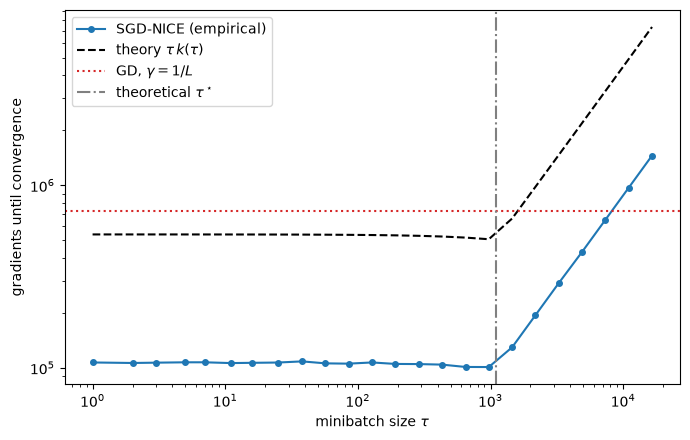

In [6]:
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(taus, grads, "o-", ms=4, label="SGD-NICE (empirical)")
ax.loglog(taus, [t * k_theory(t) for t in taus], "k--", label=r"theory $\tau\, k(\tau)$")
ax.axhline(grads_gd, color="C3", ls=":", label=r"GD, $\gamma = 1/L$")
ax.axvline(tau_star, color="gray", ls="-.", label=r"theoretical $\tau^\star$")
ax.set_xlabel(r"minibatch size $\tau$")
ax.set_ylabel("gradients until convergence")
ax.legend()
fig.tight_layout()
fig.savefig("figures/optimal_batch_size.png", dpi=150)
plt.show()